# L-Maze: Q-Learning and Double Q-Learning with Linear Approximation (Fourier Basis Features)

Q-Learning with linear function approximation is prone to the __Deadly Triad:__

* TD
* Off-policy
* Function approximation

This often leads to stability and convergence issues.

This notebook will also introduce Double Q-Learning with linear approximation.

## Installation and Setup

In [ ]:
# uncomment if needed
# %pip install gym-classics2

# if the code produces an error, then try to install the package's latest version from github:
# %pip install "gym-classics2 @ git+https://github.com/mhahsler/gym-classics2.git"

In [81]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [82]:
import gymnasium as gym
import gym_classics2

## Define a Grid World 

In [83]:
gym_env = gym.make('LMaze-v0', goal_reward = 99.0, step_reward = -1.0, tabular=False)

env = gym_env.unwrapped
env.reset(seed=SEED)

((3, 2), {})

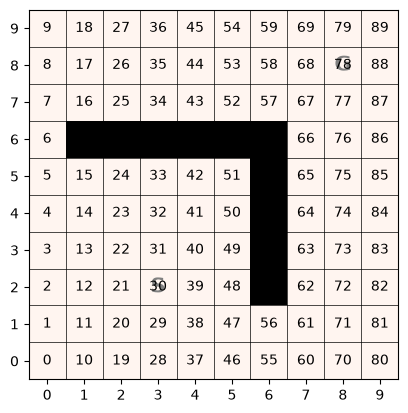

In [84]:
env.image()

Helper to plot a solution given the learned weight vector $\mathbf{w}$.

In [85]:
from gym_classics2.algorithms.linear_approximation import q_hat
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

# helper to visualize the learned policy and value function 
def plot_solution(w, title=None, clim=None):
    Q = np.array([[q_hat(s, a, w, env, state_features) for a in env.actions()] for s in env.states()])
    V = np.max(Q, axis=1)
    pol = np.argmax(Q, axis=1)
    env.image(V, policy=pol, title=title, clim=clim)
    env.image(V, episode=sample_episode(env, policy=pol, max_len=100, rng=rng), title='Found Path', clim=clim)

## Define a Fourier Basis Transformation

In [86]:
from gym_classics2.algorithms.linear_approximation import q_hat, transformation_fourier_basis

trans_fb = transformation_fourier_basis(min = np.array([0,0]), max = np.array(env.dims)-1, order=8)

# define the Fourier basis features used by semi-gradient Sarsa
def state_features(s, env):
    return trans_fb(s)

# Simple Semi-Gradient Q-Learning

This is like semi-gradient Sarsa(0), just the target calculated with the best next action instead of the actual chosen action.

In [87]:
from tqdm import tqdm
import warnings
from gym_classics2.utils import get_rng, random_argmax
from gym_classics2.algorithms.schedules import Schedule, ConstantSchedule, LinearDecaySchedule
from gym_classics2.algorithms.linear_approximation import get_rng, state_action_features, epsilon_greedy_action_w

def semi_gradient_QLearning(env, state_features, n, epsilon, alpha, discount, w=None,
                          max_episode_length=1000, verbose=False,
                          history=False, rng=None):
    """Run semi-gradient Q-Learning with function approximation for control.

    Args:
        env: Episodic environment used to generate experience.
        state_features: Callable converting ``(state, env)`` to a feature vector.
        n: Number of training episodes.
        epsilon: Exploration rate or schedule for the epsilon-greedy policy.
        alpha: Step size or schedule.
        discount: Discount factor in ``[0, 1]``.
        w: Initial action-value weight vector. If omitted, initialize it to zeros.
        max_episode_length: Maximum number of steps per episode.
        verbose: Whether to print step-by-step diagnostics.
        history: Whether to return weights, returns, and episode lengths collected
            during training.
        rng: NumPy generator or integer seed for exploration and tie-breaking.

    Returns:
        Learned weight vector. If ``history`` is true, returns ``(w, history)``.

    Raises:
        FloatingPointError: A NumPy operation overflows or is invalid during
            training. Try a smaller step size and check the feature values.
    """
    
    assert discount >= 0 and discount <= 1, "Discount must be in [0,1]"
    assert n > 0, "Number of episodes must be positive"
    assert max_episode_length > 0, "Max episode length must be positive"

    rng = get_rng(rng)

    if isinstance(env.observation_space, gym.spaces.Discrete):
        warnings.warn("The environment has a discrete state space. Consider using a tabular method instead of function approximation.")

    if not isinstance(alpha, Schedule):
        alpha = ConstantSchedule(alpha)
    if not isinstance(epsilon, Schedule):
        epsilon = ConstantSchedule(epsilon)

    if w is None:
        state, _ = env.reset()
        w = np.zeros(len(state_action_features(state, 0, env, state_features)))

    if history:
        ws = []
        ws.append(w.copy())
        returns = []
        ep_lens = []
    
    for episode in tqdm(range(n), desc="Semi-Gradient Q-Learning", disable=verbose):
        state, _ = env.reset()
        action = epsilon_greedy_action_w(
            state, w, env, state_features, epsilon(episode), rng=rng
        )
        done = False

        i = 0
        if history:
            G = 0
        while not done and i < max_episode_length:
            

            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            
            x = state_action_features(state, action, env, state_features)
            
            if terminated:
                next_action = None
                w += alpha(episode) * (reward - q_hat(state, action, w, env, state_features)) * x
                
            else:
                next_action = epsilon_greedy_action_w(
                    next_state, w, env, state_features, epsilon(episode), rng=rng
                )
                # the difference to Sarsa is the max operator in the update rule
                w += (
                    alpha(episode) * 
                      (reward + discount * max(q_hat(next_state, a, w, env, state_features) for a in range(env.action_space.n)) 
                       - q_hat(state, action, w, env, state_features)) * x
                      )

            if verbose:
                print (f"Episode {episode+1}, Step {i+1}: S={state}, A={action}, R={reward}, S'={next_state}, w={w}")

            state = next_state
            action = next_action
            i += 1
            
            if history:
                G += reward * (discount ** (i-1))
            
        if history:
            ws.append(w.copy())
            returns.append(G)
            ep_lens.append(i)

    if history:
        return w, {'ws': ws, 'returns': returns, 'ep_lens': ep_lens}
    
    return w  

In [97]:
rng = np.random.default_rng(SEED)

w, history = semi_gradient_QLearning(env, state_features, n=5000, 
                                   epsilon=.1, 
                                   alpha=0.001,
                                   discount=1,
                                   max_episode_length=500,
                                   verbose=False, history=True, rng=rng)

Semi-Gradient Q-Learning: 100%|██████████| 5000/5000 [00:56<00:00, 88.01it/s] 


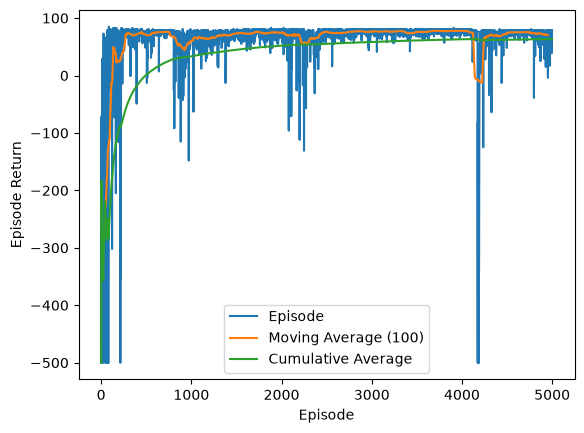

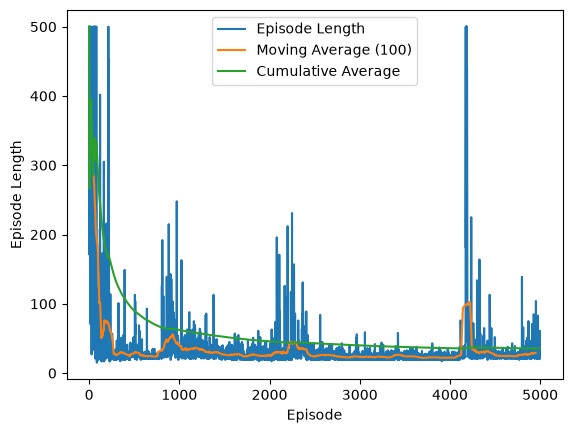

In [98]:
from gym_classics2.performance import plot_returns, plot_episode_lengths
plot_returns(history["returns"])
plot_episode_lengths(history["ep_lens"])

Learned value function.

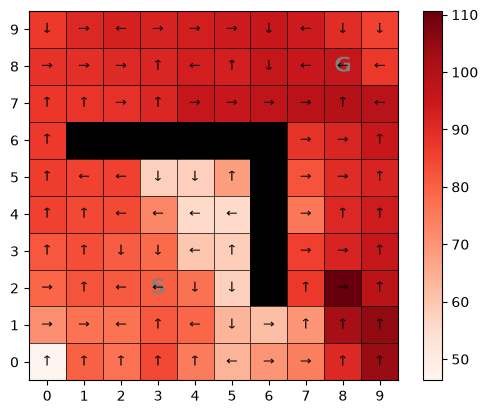

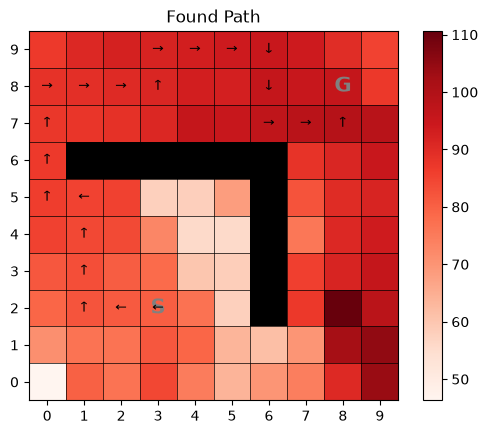

In [99]:
plot_solution(w)

The algorithm is still relatively stable because:
* The problem is simple
* The gradient for linear approximation is constant $x(s,a)$. As long as $x(s,a)$ is scaled appropriately, it does not explode or vanish.
* I choose a small learning rate $\alpha$.

But it did not converge to a local optimum.

Here is the learned value function.

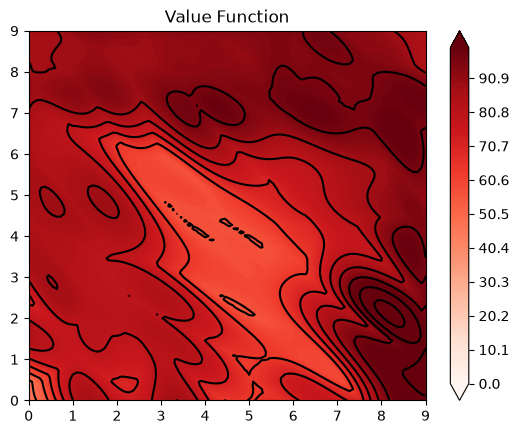

In [100]:
from matplotlib import pyplot as plt

def q_hat_grid(x, y, a, w):
    x_s = trans_fb(np.array([x, y]))
    sf_len = len(x_s) -1
    active_weights = [0] + list(range(a*sf_len+1, a*sf_len+sf_len+1))
    return np.dot(w[active_weights], x_s)

x = np.linspace(0, env.dims[0]-1, 100)
y = np.linspace(0, env.dims[1]-1, 100)
X, Y = np.meshgrid(x, y)

# plot the value function
Z = np.array([np.max([q_hat_grid(x, y, a, w) for a in range(env.action_space.n)]) for x, y in zip(np.ravel(X), np.ravel(Y))]).reshape(X.shape)
plt.contourf(X, Y, Z, cmap='Reds', levels=np.linspace(0, 100.0, 100), extend='both')
plt.colorbar(extend='both')
plt.title('Value Function')
plt.contour(X, Y, Z, colors='black', levels=10) # Contour lines
plt.show()

The value function approximation can be improved using higher order features.

## Double Q-Learning

Q-learning uses the same estimates to select and evaluate the maximizing action, which causes maximization bias. Double Q-learning keeps two weight vectors $\mathbf{w}_1$ and $\mathbf{w}_2$. With probability 0.5 we update $\mathbf{w}_1$ using $\mathbf{w}_1$ to select the best next action and $\mathbf{w}_2$ to evaluate it (and vice versa):

$$\mathbf{w}_1 \leftarrow \mathbf{w}_1 + \alpha \left[R + \gamma \hat q(S', \arg\max_a \hat q(S',a,\mathbf{w}_1), \mathbf{w}_2) - \hat q(S,A,\mathbf{w}_1)\right] \nabla \hat q(S,A,\mathbf{w}_1)$$

The behavior policy is $\epsilon$-greedy with respect to $\mathbf{w}_1 + \mathbf{w}_2$. We return the average of the two weight vectors.

In [92]:
from gym_classics2.algorithms.schedules import ConstantSchedule

def semi_gradient_DoubleQLearning(env, state_features, n, epsilon, alpha, discount,
                                  max_episode_length=1000, history=False, rng=None):
    """Semi-gradient Double Q-Learning with linear function approximation.

    Returns the average of the two learned weight vectors. If ``history`` is true,
    returns ``(w, history)`` with the same keys as ``semi_gradient_QLearning``.
    """
    assert 0 <= discount <= 1, "Discount must be in [0,1]"
    rng = get_rng(rng)

    if not isinstance(alpha, Schedule):
        alpha = ConstantSchedule(alpha)
    if not isinstance(epsilon, Schedule):
        epsilon = ConstantSchedule(epsilon)

    state, _ = env.reset()
    w1 = np.zeros(len(state_action_features(state, 0, env, state_features)))
    w2 = w1.copy()
    n_actions = env.action_space.n

    if history:
        ws, returns, ep_lens = [(w1 + w2) / 2], [], []

    for episode in tqdm(range(n), desc="Semi-Gradient Double Q-Learning"):
        state, _ = env.reset()
        done, i, G = False, 0, 0
        while not done and i < max_episode_length:
            # behavior policy: epsilon-greedy w.r.t. w1 + w2
            action = epsilon_greedy_action_w(state, w1 + w2, env, state_features,
                                             epsilon(episode), rng=rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # randomly pick which estimate to update
            if rng.random() < 0.5:
                w_upd, w_eval = w1, w2
            else:
                w_upd, w_eval = w2, w1

            x = state_action_features(state, action, env, state_features)
            target = reward
            if not terminated:
                # select the action with w_upd, evaluate it with w_eval
                q_next = np.array([q_hat(next_state, a, w_upd, env, state_features) for a in range(n_actions)])
                best = random_argmax(q_next, rng=rng)
                target += discount * q_hat(next_state, best, w_eval, env, state_features)
            w_upd += alpha(episode) * (target - q_hat(state, action, w_upd, env, state_features)) * x

            state = next_state
            G += reward * (discount ** i)
            i += 1

        if history:
            ws.append((w1 + w2) / 2)
            returns.append(G)
            ep_lens.append(i)

    w = (w1 + w2) / 2
    if history:
        return w, {'ws': ws, 'returns': returns, 'ep_lens': ep_lens}
    return w

In [101]:
rng = np.random.default_rng(SEED)

w_dq, history_dq = semi_gradient_DoubleQLearning(env, state_features, n=5000,
                                   epsilon=0.1,
                                   alpha=0.001,
                                   discount=1,
                                   max_episode_length=500,
                                   history=True, rng=rng)

Semi-Gradient Double Q-Learning: 100%|██████████| 5000/5000 [01:04<00:00, 77.55it/s] 


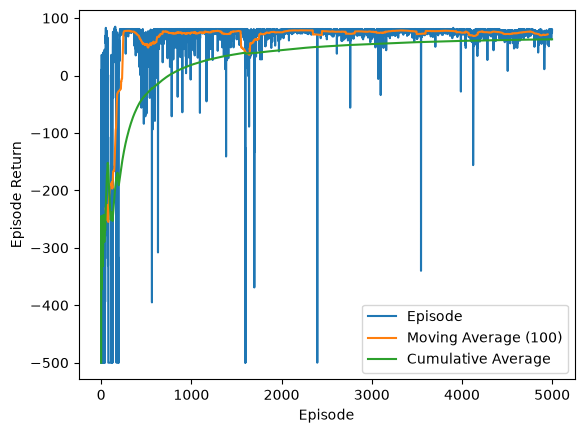

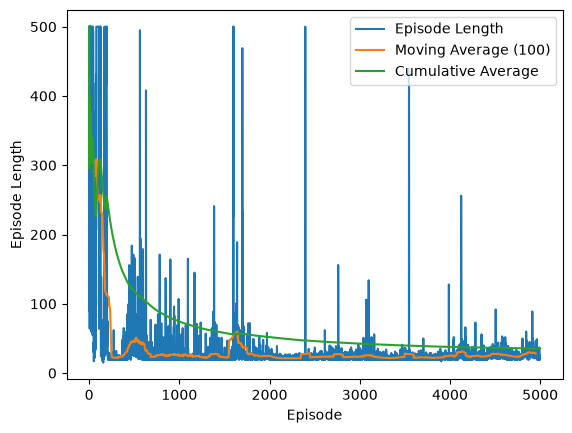

In [102]:
plot_returns(history_dq["returns"])
plot_episode_lengths(history_dq["ep_lens"])

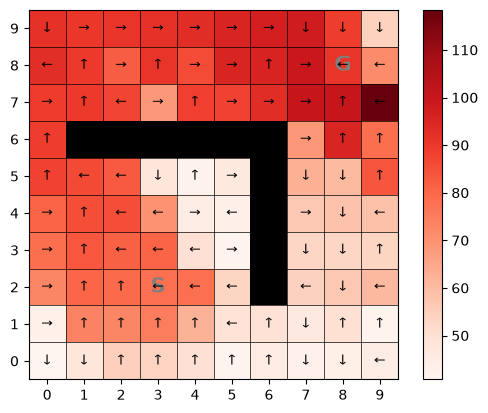

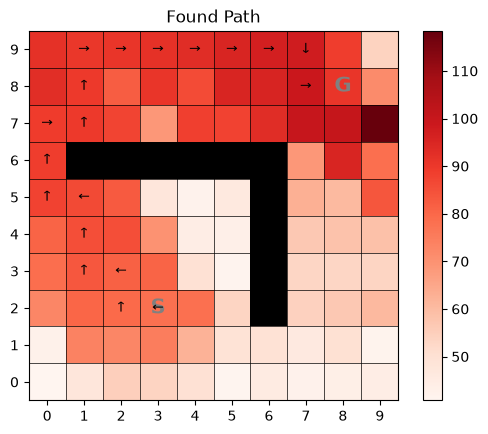

In [103]:
plot_solution(w_dq)

This is closer to a local optimum.

Double Q-learning leads to more stable learning behavior.


&copy; 2026 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)